In [1]:
from dataclasses import fields

import baostock as bs
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from datetime import datetime, timedelta

from IPython.core.compilerop import code_name
from matplotlib import rcParams # 字体
from unicodedata import normalize

rcParams['font.sans-serif'] = ['SimHei']
bs.login()
rs = bs.query_history_k_data_plus(
    'sz.000001',
    'date,close',
    start_date = '2026-01-01',
    end_date = '2026-07-21',
    frequency='d'
)

df = rs.get_data()

print(df.head())
bs.logout()

login success!
         date    close
0  2026-01-05  11.5000
1  2026-01-06  11.6700
2  2026-01-07  11.6400
3  2026-01-08  11.5100
4  2026-01-09  11.4600
logout success!


In [2]:
df['close'] = pd.to_numeric(df['close'])
df['date'] = pd.to_datetime(df ['date'])

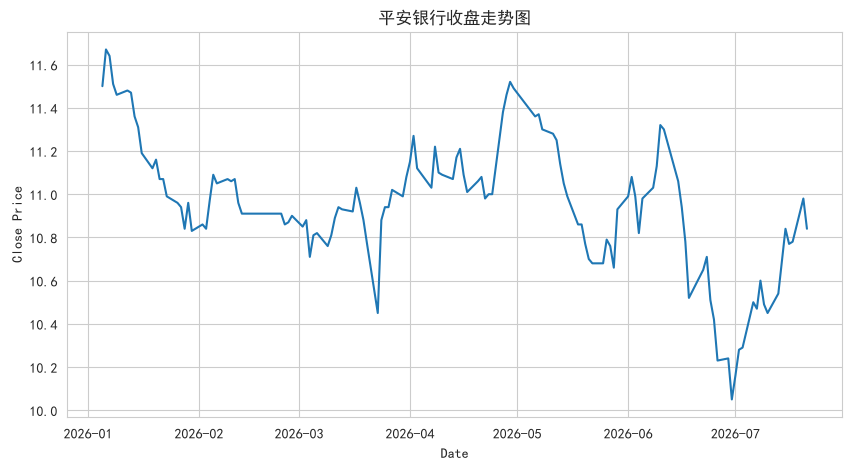

In [3]:
plt.figure(figsize=(10,5))
plt.plot(df['date'], df['close'])
plt.title('平安银行收盘走势图')
plt.xlabel('Date')
plt.ylabel('Close Price')
plt.grid(True)
plt.show()

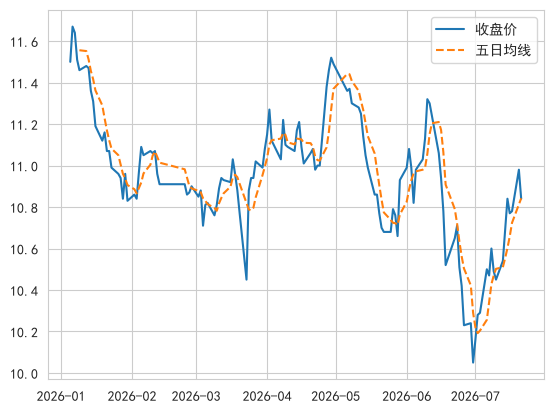

In [4]:
df['MA5'] = df['close'].rolling(5).mean()
plt.plot(df['date'], df['close'],label = '收盘价')
plt.plot(df['date'],df['MA5'],label = '五日均线',linestyle='--')
plt.legend()

In [5]:
bs.login()
rs = bs.query_history_k_data_plus(
    'sz.000001',
    'date,close',
    start_date = '2026-01-01',
    end_date = '2026-07-21',
    frequency='d',
)
df = rs.get_data()
bs.logout()

df['close'] = pd.to_numeric(df['close'])
df['date'] = pd.to_datetime(df ['date'])

first_price = df['close'].iloc[0]#第一天收盘价
last_price = df['close'].iloc[-1]#最后一天收盘价
pct_change = (last_price/first_price - 1)*100
print(f'平安银行区间涨跌幅: {pct_change:.2f}%')

login success!
logout success!
平安银行区间涨跌幅: -5.74%


In [6]:
highest = df['close'].max()
lowest = df['close'].min()
print(f'最高价: {highest:.2f}%元')
print(f'最低价: {lowest:.2f}%元')


最高价: 11.67%元
最低价: 10.05%元


C:\Users\admin\AppData\Local\Temp\ipykernel_26196\1820726352.py:14: UserWarning: Glyph 8722 (\N{MINUS SIGN}) missing from font(s) SimHei.
  plt.tight_layout()
C:\Users\admin\PycharmProjects\PythonProject\.venv\Lib\site-packages\IPython\core\pylabtools.py:170: UserWarning: Glyph 8722 (\N{MINUS SIGN}) missing from font(s) SimHei.
  fig.canvas.print_figure(bytes_io, **kw)


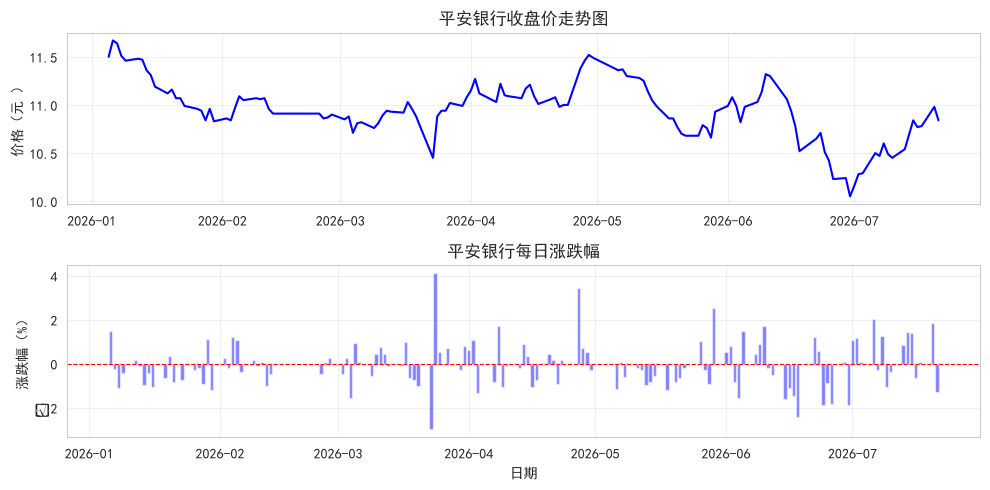

In [7]:

fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(10, 5))
ax1.plot(df['date'], df['close'], color='blue')
ax1.set_title('平安银行收盘价走势图')
ax1.set_ylabel('价格（元 ）')
ax1.grid(True, alpha=0.3)

df['daily_return'] = df['close'].pct_change() * 100
ax2.bar(df['date'], df['daily_return'], color='blue', alpha=0.5)
ax2.axhline(y=0, color='red', linestyle='--', linewidth=0.8)
ax2.set_title('平安银行每日涨跌幅')
ax2.set_xlabel('日期')
ax2.set_ylabel('涨跌幅（%）')
ax2.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

In [8]:
import baostock as bs
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import time
from matplotlib import rcParams # 字体
rcParams['font.sans-serif'] = ['SimHei']
bs.login()


# 获取全部股票基础信息
rs = bs.query_hs300_stocks()
stock_list = []
# 标准循环取值方式
while rs.error_code == '0' and rs.next():
    stock_list.append(rs.get_row_data())

# 生成DataFrame
stock_df = pd.DataFrame(stock_list, columns=rs.fields)

# 退出登录
bs.logout()

# 打印结果
print(f'沪深300市场共有：{len(stock_df)}只股票')
print(stock_df.head(20))


login success!
logout success!
沪深300市场共有：300只股票
    updateDate       code code_name
0   2026-07-27  sh.600000      浦发银行
1   2026-07-27  sh.600009      上海机场
2   2026-07-27  sh.600010      包钢股份
3   2026-07-27  sh.600011      华能国际
4   2026-07-27  sh.600015      华夏银行
5   2026-07-27  sh.600016      民生银行
6   2026-07-27  sh.600018      上港集团
7   2026-07-27  sh.600019      宝钢股份
8   2026-07-27  sh.600023      浙能电力
9   2026-07-27  sh.600025      华能水电
10  2026-07-27  sh.600026      中远海能
11  2026-07-27  sh.600027      华电国际
12  2026-07-27  sh.600028      中国石化
13  2026-07-27  sh.600029      南方航空
14  2026-07-27  sh.600030      中信证券
15  2026-07-27  sh.600031      三一重工
16  2026-07-27  sh.600036      招商银行
17  2026-07-27  sh.600039      四川路桥
18  2026-07-27  sh.600048      保利发展
19  2026-07-27  sh.600050      中国联通


In [9]:
lg = bs.login()

rs = bs.query_hs300_stocks()
hs300_list = []
while rs.error_code == '0' and rs.next():
    hs300_list.append(rs.get_row_data())

stock_list = pd.DataFrame(hs300_list, columns=rs.fields)
test_stock = stock_list.head(10)
print('测试股票列表：')
print(test_stock)

login success!
测试股票列表：
   updateDate       code code_name
0  2026-07-27  sh.600000      浦发银行
1  2026-07-27  sh.600009      上海机场
2  2026-07-27  sh.600010      包钢股份
3  2026-07-27  sh.600011      华能国际
4  2026-07-27  sh.600015      华夏银行
5  2026-07-27  sh.600016      民生银行
6  2026-07-27  sh.600018      上港集团
7  2026-07-27  sh.600019      宝钢股份
8  2026-07-27  sh.600023      浙能电力
9  2026-07-27  sh.600025      华能水电


In [10]:

# 只取前10只测试
test_stocks = stock_list.head(10)

# 用来存结果
results = []

for i, row in test_stocks.iterrows():
    code = row['code']
    name = row['code_name']

    print(f"正在处理 {i+1}/{len(test_stocks)}: {code} {name}")

    # 取最近60天数据
    rs = bs.query_history_k_data_plus(
        code,
        "date,close",
        start_date="2026-05-01",
        end_date="2026-07-21",
        frequency="d"
    )

    # 用while循环取值（更稳定）
    data = []
    while rs.error_code == '0' and rs.next():
        data.append(rs.get_row_data())

    # 如果有数据，计算涨跌幅
    if len(data) >= 2:
        df = pd.DataFrame(data, columns=rs.fields)
        df['close'] = pd.to_numeric(df['close'])

        first_price = df['close'].iloc[0]
        last_price = df['close'].iloc[-1]
        pct = (last_price / first_price - 1) * 100
        results.append({
            'code': code,
            'name': name,
            'return': pct,
            'last_price': last_price
        })

    time.sleep(0.5)

# 转成表格
df_results = pd.DataFrame(results)
print("\\n所有股票涨跌幅：")
print(df_results)

# 按涨跌幅排序
df_sorted = df_results.sort_values('return', ascending=False)
print("\\n🏆 涨幅排名：")
print(df_sorted)

正在处理 1/10: sh.600000 浦发银行
正在处理 2/10: sh.600009 上海机场
正在处理 3/10: sh.600010 包钢股份
正在处理 4/10: sh.600011 华能国际
正在处理 5/10: sh.600015 华夏银行
正在处理 6/10: sh.600016 民生银行
正在处理 7/10: sh.600018 上港集团
正在处理 8/10: sh.600019 宝钢股份
正在处理 9/10: sh.600023 浙能电力
正在处理 10/10: sh.600025 华能水电
\n所有股票涨跌幅：
        code  name     return  last_price
0  sh.600000  浦发银行  -2.505447        8.95
1  sh.600009  上海机场 -13.732652       23.62
2  sh.600010  包钢股份 -23.049645        2.17
3  sh.600011  华能国际   1.118881        7.23
4  sh.600015  华夏银行   1.780415        6.86
5  sh.600016  民生银行  -5.149051        3.50
6  sh.600018  上港集团   3.162055        5.22
7  sh.600019  宝钢股份  -8.214850        5.81
8  sh.600023  浙能电力  -7.638889        5.32
9  sh.600025  华能水电   6.256517       10.19
\n🏆 涨幅排名：
        code  name     return  last_price
9  sh.600025  华能水电   6.256517       10.19
6  sh.600018  上港集团   3.162055        5.22
4  sh.600015  华夏银行   1.780415        6.86
3  sh.600011  华能国际   1.118881        7.23
0  sh.600000  浦发银行  -2.505447        8.95
5  s

In [11]:
top5 = df_sorted.head(5)
top5_codes = top5['code'].tolist()
top5_names = top5['name'].tolist()

print('top 5 强势股票：')
print(top5[['code', 'name', 'return']])
bs.login()
plt.figure(figsize=(12, 6))


top 5 强势股票：
        code  name    return
9  sh.600025  华能水电  6.256517
6  sh.600018  上港集团  3.162055
4  sh.600015  华夏银行  1.780415
3  sh.600011  华能国际  1.118881
0  sh.600000  浦发银行 -2.505447
login success!


<Figure size 1200x600 with 0 Axes>

<Figure size 1200x600 with 0 Axes>

logout success!


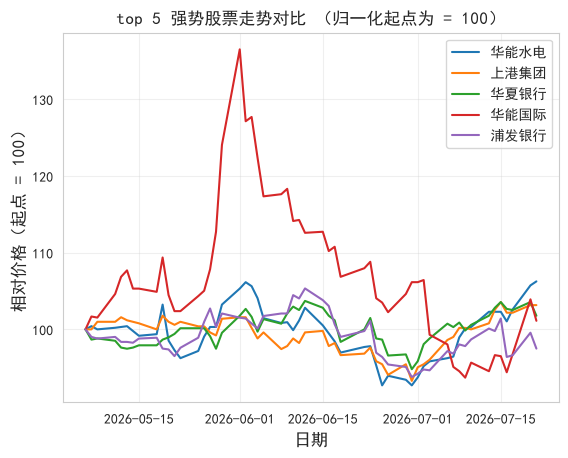

In [12]:
for code,name in zip(top5_codes,top5_names):
    rs = bs.query_history_k_data_plus(
        code,
        'date,close',
        start_date="2026-05-01",
        end_date="2026-07-21",
        frequency="d"

    )
    data = []
    while rs.error_code == '0' and rs.next():
        data.append(rs.get_row_data())

    if len(data) >= 2:
        df = pd.DataFrame(data, columns=rs.fields)
        df['close'] = pd.to_numeric(df['close'])
        df['date'] = pd.to_datetime(df['date'])

        normalized = df['close'] / df['close'].iloc[0] * 100
        plt.plot(df['date'], normalized, label = name,linewidth=1.5)

bs.logout()

plt.title('top 5 强势股票走势对比 （归一化起点为 = 100）', fontsize=12)
plt.xlabel('日期', fontsize=12)
plt.ylabel('相对价格（起点 = 100）', fontsize=12)
plt.grid(True, alpha=0.3)
plt.legend()
plt.show()

In [13]:
import baostock as bs
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from datetime import datetime, timedelta

from IPython.core.compilerop import code_name
from matplotlib import rcParams # 字体
from unicodedata import normalize


In [14]:
def stock_screener(start_date, end_date,top_n = 5):
   """
   股票筛选器函数
   参数:
        start_date:开始日期，格式'2026-05-01'
        end_date:结束日期'2026-07-21'
        top_n:返回前N只股票，默认5
    返回:
        df_sorted: 按涨幅排序的全部结果
        top_stocks: 排名前N的股票
    """

   print(f'开始筛选股票')
   print(f'{start_date}至 {end_date}')
   print(f'返回前 {top_n}名')
   print('-'*40)

   bs.login()

   rs = bs.query_hs300_stocks()
   stock_list = []
   while rs.error_code == '0' and rs.next():
       stock_list.append(rs.get_row_data())
   stock_df = pd.DataFrame(stock_list, columns=rs.fields)


   print(f'获取到{len(stock_df)}只沪深300股票')

   results = []
   for i,row in stock_df .iterrows():
       code = row['code']
       name = row['code_name']

       #每50只打印一次进度
       if i % 50 == 0:
           print(f'正在处理：{i+1}/{len(stock_df)}')

       rs = bs.query_history_k_data_plus(
           code,
           'date,close',
           start_date=start_date,
           end_date=end_date,
           frequency="d"
       )
       data = []
       while rs.error_code == '0' and rs.next():
           data.append(rs.get_row_data())

       if len (data) >= 2:
           df = pd.DataFrame(data, columns=rs.fields)


           df['close'] = pd.to_numeric(df['close'])
           first_price = df['close'].iloc[0]
           last_price = df['close'].iloc[-1]
           pct = (last_price / first_price - 1) * 100

           results.append({
               'code': code,
               'name': name,
               'return': pct,
               'last_price': last_price
           })

       time.sleep(0.5)

   df_results = pd.DataFrame(results)
   df_sorted = df_results.sort_values('return', ascending=False)

   top_stocks = df_sorted.head(top_n)

   print('-'*40)
   print(f'筛选成功!共 {len(df_results)}只股票数据')
   print(f'涨幅排名前{top_n}:')
   print(top_stocks[['code', 'name', 'return']])
   print()

   return df_sorted,top_stocks

def plot_top_stocks(top_stocks,start_date, end_date):
    """
    画股票走势图
    :param top_stocks:
    :param start_date:
    :param end_date:
    :return:
    """
    bs.login()
    plt.figure(figsize=(12,6))

    top_codes = top_stocks['code'].tolist()
    top_names = top_stocks['name'].tolist()
    for code ,name in zip(top_codes,top_names):
        rs = bs.query_history_k_data_plus(
            code,
            'date,close',
            start_date=start_date,
            end_date=end_date,
            frequency="d"

        )
        data = []

        while rs.error_code == '0' and rs.next():
            data.append(rs.get_row_data())

        if len(data) >= 2:
            df = pd.DataFrame(data, columns=rs.fields)
            df['close'] = pd.to_numeric(df['close'])
            df['date'] = pd.to_datetime(df['date'])
            normalized = df['close'] / df['close'].iloc[0] * 100
            plt.plot(df['date'], normalized, label = name,linewidth=1.5)

        bs.logout()

    plt.title(f'TOP{len(top_stocks)}强势股票走势对比（归一化起点  = 100）')
    plt.xlabel('日期', fontsize=12)
    plt.ylabel('相对价格（起点 = 100）', fontsize=12)
    plt.legend(loc='upper left')
    plt.grid(True, alpha=0.3)
    plt.show()